# Data Loading

In [ ]:
%%time

#### NOte: rename weight column to weight_algo column

import kpex_dev
import data_splits
import warnings
import pandas as pd
import numpy as np
from openpyxl import Workbook

# create once, pass around multiple times for writing metrics
wb = Workbook()

warnings.filterwarnings('ignore')

timeout_replacement = 1800  # max timeout replacement
file_path = r"..\input_data\results-filtered-dataset.txt"


feature_cols = data_splits.feature_cols
algorithms = data_splits.algorithms


CPU times: total: 2.55 s
Wall time: 9.34 s


In [2]:
# Loading and preprocessing data
cat_df= kpex_dev.load_excel_data(file_path, timeout_replacement)
kpex_dev.process_kcore_list_to_statistics(cat_df)

# Selecting weight scheme
epsilon = 0.001 # need to set !!!
scheme = kpex_dev.W_TIME_MIN_X_W_LOG_TIME_RATIO # Change this and analyse!!

# Assigning weights
kpex_dev.assign_weights(cat_df, scheme, epsilon)

# kpex_dev.export_sorted(cat_df)

# Data reformatting
cat_df = kpex_dev.post_process_data(cat_df)
cat_df

,dataset,k_value,n,m,d_avg,d_max,core_max,core_min,shell_num,shell_avgSize,...,UMKP-S,UMKP-R,UMKP-P,UMKP+-S,UMKP+-R,UMKP+-P,kPEX,kPEX-S,kPEX-R,kPEX-P
0,12month1,20,52328,1585220,30.294,9214,57,19,39,16785.102564,...,1800.000000,1800.000000,1800.000000,131.0240,121.2490,117.7020,116.0158,124.7390,125.8084,126.1804
1,130bit,8,584,6059,10.375,322,12,8,5,564.400000,...,3.196156,1.179364,0.653300,2.3643,0.7011,0.8350,1.4934,0.4922,0.9836,1.7554
2,130bit,9,584,6059,10.375,322,12,8,5,564.400000,...,39.330518,2.159862,2.485482,34.7253,3.2734,3.0159,38.6679,4.9357,22.5385,47.5120
3,130bit,10,583,6051,10.379,321,12,9,4,559.500000,...,9.695851,7.271823,1.946958,9.4931,3.0985,2.4184,10.8117,2.0049,10.4852,12.4310
4,144,4,144319,1072349,7.430,26,9,7,3,140266.333333,...,0.588537,0.539013,0.755349,1.0679,1.0694,0.9626,0.9761,1.0700,1.0626,1.1065
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4351,zhishi-zhwiki-internallink,7,4666,248342,53.224,2014,99,19,81,2293.913580,...,2.349277,2.272406,2.238443,1.8562,2.2227,2.2188,1.8133,1.8370,2.2205,2.1942
4352,zhishi-zhwiki-internallink,8,6109,313420,51.305,2421,101,19,83,2731.265060,...,3.851166,3.097895,2.829056,2.8021,2.4912,2.5297,2.8437,2.3888,2.3317,2.8890
4353,zhishi-zhwiki-internallink,9,5981,309664,51.775,2406,101,20,82,2688.695122,...,6.984801,2.970734,2.855774,2.4142,2.4424,2.7942,2.4207,2.5012,2.5222,2.9436
4354,zhishi-zhwiki-internallink,10,4419,244006,55.217,1989,99,22,78,2204.871795,...,13.381666,7.638818,3.442978,1.8692,1.8513,1.6981,1.7289,1.7092,1.7741,1.7088


## Scheme 2 - Hierarchial model


<!-- - Hierarchial model -->
Algorithms are divided into groups and sub-groups, each having their own classifier.
At each level of the hierarchy, we apply a confidence threshold τ to prevent low-confidence predictions from propagating downstream.

![image.png](attachment:image.png)

Tie Breaking and Data Splitting

In [12]:
ALT_RB_ALGOS = ["UMKP+-S", "UMKP+-R", "UMKP+-P"]
NO_ALT_RB_ALGOS = ["UMKP-S", "UMKP-R", "UMKP-P"]
SPARSE_ALGOS = ALT_RB_ALGOS + NO_ALT_RB_ALGOS
DENSE_ALGOS = ["kPEX", "kPEX-S", "kPEX-R", "kPEX-P"]

ALL_ALGOS = ALT_RB_ALGOS + NO_ALT_RB_ALGOS + DENSE_ALGOS


Step 1: Fastest leaf algorithm per row

In [5]:
def get_fastest_algorithm(row, algorithms):
    times = np.array([row[a] for a in algorithms], dtype=float)
    return algorithms[np.argmin(times)]

cat_df["y_algo"] = cat_df.apply(
    lambda r: get_fastest_algorithm(r, ALL_ALGOS),
    axis=1
)


Step 2: Create y_group

In [6]:
def map_group(algo):
    if algo in DENSE_ALGOS:
        return "Dense"
    return "Sparse"

cat_df["y_group"] = cat_df["y_algo"].apply(map_group)


Step 3: Create y_sparse_subgroup

In [7]:
def map_sparse_subgroup(algo):
    if algo in ALT_RB_ALGOS:
        return "AltRB"
    if algo in NO_ALT_RB_ALGOS:
        return "No-AltRB"
    return None

cat_df["y_sparse_subgroup"] = cat_df["y_algo"].apply(map_sparse_subgroup)


Step 4: Deriving Weights for Each Classifier

In [14]:
# Classifier 1 (Sparse vs Dense)
# weight should reflect relative difficulty between Sparse and Dense.
def compute_group_weight(row, epsilon=1e-3):
    sparse_vals = np.array([row[a] for a in SPARSE_ALGOS], dtype=float)
    dense_vals = np.array([row[a] for a in DENSE_ALGOS], dtype=float)

    sparse_best = sparse_vals.min()
    dense_best = dense_vals.min()

    vals = np.array([sparse_best, dense_best])

    min_val = vals.min()
    max_val = vals.max()

    if min_val == 0:
        ratio = max_val / epsilon
    else:
        ratio = max_val / min_val

    return np.log(1 + min_val) + np.log(ratio)

cat_df["weight_group"] = cat_df.apply(compute_group_weight, axis=1)


# Classifier 2 (Sparse: AltRB vs No-AltRB); distinguishes within sparse category
# weight should reflect relative difficulty between AltRB and No-AltRB.
# We recompute using only sparse algorithms

def compute_sparse_weight(row, epsilon=1e-3):
    vals = np.array([row[a] for a in SPARSE_ALGOS], dtype=float)
    min_val = vals.min()
    max_val = vals.max()

    if min_val == 0:
        ratio = max_val / epsilon
    else:
        ratio = max_val / min_val

    return np.log(1 + min_val) + np.log(ratio)

cat_df["weight_sparse_subgroup"] = cat_df.apply(compute_sparse_weight, axis=1)


# Classifier 3 (AltRB leaf) Only AltRB rows matter
cat_df["weight_altRB"] = np.where(
    cat_df["y_sparse_subgroup"] == "AltRB",
    cat_df["weight"],
    0
)

# Classifier 4 (No-AltRB leaf)
cat_df["weight_noAltRB"] = np.where(
    cat_df["y_sparse_subgroup"] == "No-AltRB",
    cat_df["weight"],
    0
)


# Classifier 5 (Dense leaf)
cat_df["weight_dense"] = cat_df["weight"]



In [219]:
cat_df

,dataset,k_value,n,m,d_avg,d_max,core_max,core_min,shell_num,shell_avgSize,...,y_algo,y_group,y_sparse_subgroup,weight_group,weight_sparse_subgroup,weight_altRB,weight_noAltRB,weight_dense,predicted,correct
0,12month1,20,52328,1585220,30.294,9214,57,19,39,16785.102564,...,kPEX,Dense,None,4.776739,7.504002,0.000000,0.000000,318.093925,Sparse,False
1,130bit,8,584,6059,10.375,322,12,8,5,564.400000,...,kPEX-S,Dense,None,0.683403,2.090441,0.000000,0.000000,0.920817,Dense,True
2,130bit,9,584,6059,10.375,322,12,8,5,564.400000,...,UMKP-R,Sparse,No-AltRB,1.976979,4.052485,0.000000,6.675999,6.675999,Dense,False
3,130bit,10,583,6051,10.379,321,12,9,4,559.500000,...,UMKP-P,Sparse,No-AltRB,1.110099,2.686203,0.000000,3.609514,3.609514,Sparse,True
4,144,4,144319,1072349,7.430,26,9,7,3,140266.333333,...,UMKP-R,Sparse,No-AltRB,1.024967,1.116255,0.000000,0.387668,0.387668,Sparse,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4351,zhishi-zhwiki-internallink,7,4666,248342,53.224,2014,99,19,81,2293.913580,...,kPEX,Dense,None,1.057741,1.285068,0.000000,0.000000,0.469571,Dense,True
4352,zhishi-zhwiki-internallink,8,6109,313420,51.305,2421,101,19,83,2731.265060,...,kPEX-R,Dense,None,1.269650,1.685857,0.000000,0.000000,1.169997,Dense,True
4353,zhishi-zhwiki-internallink,9,5981,309664,51.775,2406,101,20,82,2688.695122,...,UMKP+-S,Sparse,AltRB,1.230632,2.290312,2.564770,0.000000,2.564770,Dense,False
4354,zhishi-zhwiki-internallink,10,4419,244006,55.217,1989,99,22,78,2204.871795,...,UMKP+-P,Sparse,AltRB,0.998829,3.056923,3.505516,0.000000,3.505516,Dense,False


### Classifiers

In [220]:
import numpy as np

class HierarchicalClassifier5:
    def __init__(
        self,
        group_clf,
        sparse_subgroup_clf,
        altRB_clf,
        noAltRB_clf,
        dense_clf,
        tau_group=0.9,
        tau_sparse=0.8,
        tau_algo=0.6,
        fallback_label=None
    ):
        self.group_clf = group_clf
        self.sparse_subgroup_clf = sparse_subgroup_clf
        self.altRB_clf = altRB_clf
        self.noAltRB_clf = noAltRB_clf
        self.dense_clf = dense_clf

        self.tau_group = tau_group
        self.tau_sparse = tau_sparse
        self.tau_algo = tau_algo

        self.fallback_label = fallback_label

    # --------------------------------------------------
    def fit(self, X,
        y_group,                # Sparse / Dense
        y_sparse_subgroup,      # AltRB / No-AltRB (only for sparse rows)
        y_algo,
        weight_group=None,
        weight_sparse=None,
        weight_altRB=None,
        weight_noAltRB=None,
        weight_dense=None):

        # Convert to numpy for safe boolean indexing
        X = np.asarray(X)
        y_group = np.asarray(y_group)
        y_sparse_subgroup = np.asarray(y_sparse_subgroup)
        y_algo = np.asarray(y_algo)

        if weight_group is not None:
            weight_group = np.asarray(weight_group)
        if weight_sparse is not None:
            weight_sparse = np.asarray(weight_sparse)
        if weight_altRB is not None:
            weight_altRB = np.asarray(weight_altRB)
        if weight_noAltRB is not None:
            weight_noAltRB = np.asarray(weight_noAltRB)
        if weight_dense is not None:
            weight_dense = np.asarray(weight_dense)

        # ---------------- Stage 1 ----------------
        if weight_group is not None:
            self.group_clf.fit(X, y_group, sample_weight=weight_group)
        else:
            self.group_clf.fit(X, y_group)

        # ---------------- Stage 2 (Sparse only) ----------------
        sparse_idx = (y_group == "Sparse")

        if weight_sparse is not None:
            self.sparse_subgroup_clf.fit(
                X[sparse_idx],
                y_sparse_subgroup[sparse_idx],
                sample_weight=weight_sparse[sparse_idx]
            )
        else:
            self.sparse_subgroup_clf.fit(
                X[sparse_idx],
                y_sparse_subgroup[sparse_idx]
            )

        # ---------------- Stage 3 (AltRB only) ----------------
        alt_idx = (y_sparse_subgroup == "AltRB")

        if weight_altRB is not None:
            self.altRB_clf.fit(
                X[alt_idx],
                y_algo[alt_idx],
                sample_weight=weight_altRB[alt_idx]
            )
        else:
            self.altRB_clf.fit(
                X[alt_idx],
                y_algo[alt_idx]
            )

        # ---------------- Stage 4 (No-AltRB only) ----------------
        noalt_idx = (y_sparse_subgroup == "No-AltRB")

        if weight_noAltRB is not None:
            self.noAltRB_clf.fit(
                X[noalt_idx],
                y_algo[noalt_idx],
                sample_weight=weight_noAltRB[noalt_idx]
            )
        else:
            self.noAltRB_clf.fit(
                X[noalt_idx],
                y_algo[noalt_idx]
            )

        # ---------------- Stage 5 (Dense only) ----------------
        dense_idx = (y_group == "Dense")

        if weight_dense is not None:
            self.dense_clf.fit(
                X[dense_idx],
                y_algo[dense_idx],
                sample_weight=weight_dense[dense_idx]
            )
        else:
            self.dense_clf.fit(
                X[dense_idx],
                y_algo[dense_idx]
            )

        self.classes_ = np.unique(y_algo)
        return self


    # --------------------------------------------------
    def _confident(self, probs, tau):
        idx = np.argmax(probs)
        return probs[idx] >= tau, idx

    # --------------------------------------------------
    def predict(self, X):
        preds = []

        for x in X:
            x = np.asarray(x).reshape(1, -1)

            # ----- Stage 1: Sparse vs Dense -----
            p_group = self.group_clf.predict_proba(x)[0]
            ok, idx = self._confident(p_group, self.tau_group)
            if not ok:
                preds.append(self.fallback_label)
                continue

            group = self.group_clf.classes_[idx]

            # ----- Dense branch -----
            if group == "Dense":
                p_alg = self.dense_clf.predict_proba(x)[0]
                ok, idx = self._confident(p_alg, self.tau_algo)
                if not ok:
                    preds.append(self.fallback_label)
                    continue
                preds.append(self.dense_clf.classes_[idx])
                continue

            # ----- Sparse branch -----
            p_sparse = self.sparse_subgroup_clf.predict_proba(x)[0]
            ok, idx = self._confident(p_sparse, self.tau_sparse)
            if not ok:
                preds.append(self.fallback_label)
                continue

            sparse_group = self.sparse_subgroup_clf.classes_[idx]

            if sparse_group == "AltRB":
                p_alg = self.altRB_clf.predict_proba(x)[0]
                ok, idx = self._confident(p_alg, self.tau_algo)
                if not ok:
                    preds.append(self.fallback_label)
                    continue
                preds.append(self.altRB_clf.classes_[idx])
            else:
                p_alg = self.noAltRB_clf.predict_proba(x)[0]
                ok, idx = self._confident(p_alg, self.tau_algo)
                if not ok:
                    preds.append(self.fallback_label)
                    continue
                preds.append(self.noAltRB_clf.classes_[idx])

        return np.array(preds)

    # --------------------------------------------------
    def predict_proba(self, X):
        X = np.asarray(X)
        n_samples = len(X)
        n_classes = len(self.classes_)

        proba = np.zeros((n_samples, n_classes))
        class_to_idx = {c: i for i, c in enumerate(self.classes_)}

        # Stage 1 probabilities
        p_group = self.group_clf.predict_proba(X)

        for i in range(n_samples):
            p_sparse = p_group[i, list(self.group_clf.classes_).index("Sparse")]
            p_dense  = p_group[i, list(self.group_clf.classes_).index("Dense")]

            # ---------------- DENSE BRANCH ----------------
            p_dense_leaf = self.dense_clf.predict_proba(X[i].reshape(1, -1))[0]
            for alg, p_leaf in zip(self.dense_clf.classes_, p_dense_leaf):
                proba[i, class_to_idx[alg]] += p_dense * p_leaf

            # ---------------- SPARSE BRANCH ----------------
            p_sparse_sub = self.sparse_subgroup_clf.predict_proba(
                X[i].reshape(1, -1)
            )[0]

            idx_alt = list(self.sparse_subgroup_clf.classes_).index("AltRB")
            idx_no  = list(self.sparse_subgroup_clf.classes_).index("No-AltRB")

            p_alt = p_sparse * p_sparse_sub[idx_alt]
            p_no  = p_sparse * p_sparse_sub[idx_no]

            # ---- AltRB leaf ----
            p_alt_leaf = self.altRB_clf.predict_proba(
                X[i].reshape(1, -1)
            )[0]
            for alg, p_leaf in zip(self.altRB_clf.classes_, p_alt_leaf):
                proba[i, class_to_idx[alg]] += p_alt * p_leaf

            # ---- NoAltRB leaf ----
            p_no_leaf = self.noAltRB_clf.predict_proba(
                X[i].reshape(1, -1)
            )[0]
            for alg, p_leaf in zip(self.noAltRB_clf.classes_, p_no_leaf):
                proba[i, class_to_idx[alg]] += p_no * p_leaf

        return proba
    # def predict_proba(self, X):
    #     proba = np.zeros((len(X), len(self.classes_)))
    #     class_to_idx = {c: i for i, c in enumerate(self.classes_)}

    #     for i, x in enumerate(X):
    #         x = np.asarray(x).reshape(1, -1)

    #         p_group = self.group_clf.predict_proba(x)[0]
    #         group = self.group_clf.classes_[np.argmax(p_group)]

    #         if group == "Dense":
    #             p_alg = self.dense_clf.predict_proba(x)[0]
    #             algs = self.dense_clf.classes_

    #         else:
    #             p_sparse = self.sparse_subgroup_clf.predict_proba(x)[0]
    #             sparse_group = self.sparse_subgroup_clf.classes_[np.argmax(p_sparse)]

    #             if sparse_group == "AltRB":
    #                 p_alg = self.altRB_clf.predict_proba(x)[0]
    #                 algs = self.altRB_clf.classes_
    #             else:
    #                 p_alg = self.noAltRB_clf.predict_proba(x)[0]
    #                 algs = self.noAltRB_clf.classes_

    #         for a, p in zip(algs, p_alg):
    #             proba[i, class_to_idx[a]] = p

    #     return proba


In [243]:
import os
import numpy as np
import pandas as pd
from metrics import evaluate_algorithm_performance, evaluate_time_metrics, evaluate_with_tolerance, evaluate_time_metrics_with_tol 
def get_fastest_algorithms(row): 
    algorithms = data_splits.algorithms 
    times = [row[alg] for alg in algorithms] 
    min_time = min(times) 
    return [alg for alg in algorithms if row[alg] == min_time]

def run_full_evaluation_hier5(
    cat_df: pd.DataFrame,
    clf,
    features: list,
    algorithms: list,
    le=None,
    drop_indices: list = None,
    epsilon: float = 1e-3,
    tol: float = 0.0,
    save_files: bool = False,
    output_dir: str = './',
    file_suffix: str = "hierarchical_eval",
    kcore_list: bool = False,
    for_nn: bool = False
):

    results_df = cat_df.copy()

    # --------------------------------------------------
    # 1️⃣ True fastest algorithms
    # --------------------------------------------------
    results_df['fastest_algorithms'] = results_df.apply(
        get_fastest_algorithms, axis=1
    )

    # --------------------------------------------------
    # 2️⃣ Prepare features
    # --------------------------------------------------
    if kcore_list:
        X_full = results_df[features + ['kcore_list']].values
    elif for_nn:
        X_full = results_df[features + ['fastest_time']].values
    else:
        X_full = results_df[features].values

    # --------------------------------------------------
    # 3️⃣ Final Predictions
    # --------------------------------------------------
    print("Predicting final outputs...")
    y_pred = clf.predict(X_full)
    results_df['predicted'] = y_pred

    results_df['correct'] = results_df.apply(
        lambda row: row['predicted'] in row['fastest_algorithms'],
        axis=1
    )

    # --------------------------------------------------
    # 4️⃣ Final Leaf Probabilities
    # --------------------------------------------------
    proba_cols = []
    if hasattr(clf, "predict_proba"):
        print("Adding hierarchical leaf probabilities...")
        probas = clf.predict_proba(X_full)

        for i, cls in enumerate(clf.classes_):
            col = f"prob_{cls}"
            results_df[col] = probas[:, i]
            proba_cols.append(col)

    # --------------------------------------------------
    # 5️⃣ Stage-wise Probabilities
    # --------------------------------------------------
    print("Adding hierarchical stage probabilities...")

    # Stage 1
    p_group = clf.group_clf.predict_proba(X_full)
    for i, cls in enumerate(clf.group_clf.classes_):
        results_df[f"prob_stage1_{cls}"] = p_group[:, i]

    # Stage 2 (Sparse only)
    sparse_mask = results_df['y_group'] == "Sparse"
    if sparse_mask.any():
        X_sparse = X_full[sparse_mask]
        p_sparse = clf.sparse_subgroup_clf.predict_proba(X_sparse)
        for i, cls in enumerate(clf.sparse_subgroup_clf.classes_):
            results_df.loc[sparse_mask, f"prob_stage2_{cls}"] = p_sparse[:, i]

    # Stage 3 (AltRB)
    alt_mask = results_df['y_sparse_subgroup'] == "AltRB"
    if alt_mask.any():
        X_alt = X_full[alt_mask]
        p_alt = clf.altRB_clf.predict_proba(X_alt)
        for i, cls in enumerate(clf.altRB_clf.classes_):
            results_df.loc[alt_mask, f"prob_stage3_{cls}"] = p_alt[:, i]

    # Stage 4 (No-AltRB)
    noalt_mask = results_df['y_sparse_subgroup'] == "No-AltRB"
    if noalt_mask.any():
        X_noalt = X_full[noalt_mask]
        p_noalt = clf.noAltRB_clf.predict_proba(X_noalt)
        for i, cls in enumerate(clf.noAltRB_clf.classes_):
            results_df.loc[noalt_mask, f"prob_stage4_{cls}"] = p_noalt[:, i]

    # Stage 5 (Dense)
    dense_mask = results_df['y_group'] == "Dense"
    if dense_mask.any():
        X_dense = X_full[dense_mask]
        p_dense = clf.dense_clf.predict_proba(X_dense)
        for i, cls in enumerate(clf.dense_clf.classes_):
            results_df.loc[dense_mask, f"prob_stage5_{cls}"] = p_dense[:, i]

    # --------------------------------------------------
    # 6️⃣ Classification Metrics
    # --------------------------------------------------
    print("\nClassification performance:")
    if tol > 0:
        out_dict_1 = evaluate_with_tolerance(results_df, algorithms, tol=tol)
    else:
        out_dict_1 = evaluate_algorithm_performance(results_df, algorithms)

    # --------------------------------------------------
    # 7️⃣ Time Metrics
    # --------------------------------------------------
    df_time = results_df
    if drop_indices:
        df_time = df_time.drop(index=drop_indices, errors='ignore')

    if tol > 0:
        out_dict_2 = evaluate_time_metrics_with_tol(
            df_time, algorithms, tol=tol, epsilon=epsilon
        )
    else:
        out_dict_2 = evaluate_time_metrics(
            df_time, algorithms, epsilon=epsilon
        )

    # --------------------------------------------------
    # Create Top-3 Most Likely Predictions Column
    # --------------------------------------------------
    def get_top3(row):
        probs = {alg: row[f"prob_{alg}"] for alg in algorithms}
        top3 = sorted(probs.items(), key=lambda x: x[1], reverse=True)[:3]
        return top3
        # return ", ".join([alg for alg, _ in top3])

    results_df["top3_predicted"] = results_df.apply(get_top3, axis=1)
    
    # --------------------------------------------------
    # 8️⃣ Wrong Predictions
    # --------------------------------------------------
    wrong_df = results_df[~results_df['correct']].copy()

    # --------------------------------------------------
    # 9️⃣ Save Files
    # --------------------------------------------------
    if save_files:
        os.makedirs(output_dir, exist_ok=True)

        # Save full predictions
        full_path = os.path.join(
            output_dir,
            f"all_predictions_{file_suffix}.csv"
        )

        save_cols = (
            ['dataset', 'k_value', 'fastest_algorithms',
             'predicted', 'correct', 'top3_predicted']
            + algorithms
            + proba_cols
            + [c for c in results_df.columns if c.startswith("prob_stage")]
        )

        results_df[save_cols].to_csv(full_path, index=False)
        print(f"\nSaved full results to: {full_path}")

        # Save wrong predictions
        wrong_path = os.path.join(
            output_dir,
            f"wrong_predictions_{file_suffix}.csv"
        )

        wrong_df[save_cols].to_csv(wrong_path, index=False)
        print(f"Saved wrong predictions to: {wrong_path}")

    return out_dict_1, out_dict_2, results_df, wrong_df


import os
from openpyxl import Workbook, load_workbook

def write_metrics_to_excel_file(
    cls_metrics: dict,
    time_metrics: dict,
    filepath: str,
    sheet_name: str = "Metrics"
):
    """
    Append a new sheet of metrics to an Excel file (or create it if missing).
    Compatible with hierarchical metrics output.
    """

    # -----------------------------
    # 1) Open or create workbook
    # -----------------------------
    if os.path.exists(filepath):
        wb = load_workbook(filepath)
        if sheet_name in wb.sheetnames:
            wb.remove(wb[sheet_name])
    else:
        wb = Workbook()
        default = wb.sheetnames[0]
        if default == "Sheet":
            wb.remove(wb[default])

    ws = wb.create_sheet(title=sheet_name)

    rows = []

    # -----------------------------
    # 2) Overall Accuracy
    # -----------------------------
    if 'accuracy' in cls_metrics:
        rows.append([
            "Overall Accuracy (in %)",
            f"{cls_metrics['accuracy'] * 100:.2f}"
        ])
        rows.append([])

    # -----------------------------
    # 3) Precision
    # -----------------------------
    if 'precision_per_alg' in cls_metrics:
        rows.append(["Precision by Algorithm (in %):", ""])
        for alg, prec in cls_metrics['precision_per_alg'].items():
            rows.append([alg, f"{prec * 100:.2f}"])
        rows.append([])

    # -----------------------------
    # 4) Average Precision (AP)
    # -----------------------------
    if 'ap_per_alg' in cls_metrics:
        rows.append(["Average Precision (AP) by Algorithm (in %):", ""])
        for alg, ap in cls_metrics['ap_per_alg'].items():
            if ap is None:
                rows.append([alg, "N/A"])
            else:
                rows.append([alg, f"{ap * 100:.2f}"])
        rows.append([])

    # -----------------------------
    # 5) Recall
    # -----------------------------
    if 'recall_per_alg' in cls_metrics:
        rows.append(["Recall by Algorithm (in %):", ""])
        for alg, rec in cls_metrics['recall_per_alg'].items():
            rows.append([alg, f"{rec * 100:.2f}"])
        rows.append([])

    # -----------------------------
    # 6) Time Metrics
    # -----------------------------
    if time_metrics:
        rows.append(["Time Metrics", ""])
        if 'total_time_pred' in time_metrics:
            rows.append([
                "Total Predicted Time (seconds)",
                f"{time_metrics['total_time_pred']:.2f}"
            ])
        if 'total_time_opt' in time_metrics:
            rows.append([
                "Total Optimal Time (seconds)",
                f"{time_metrics['total_time_opt']:.2f}"
            ])
        if 'time_ratio' in time_metrics:
            rows.append([
                "Time Ratio (pred/opt)",
                f"{time_metrics['time_ratio']:.3f}"
            ])
        if 'avg_overhead_per_case' in time_metrics:
            rows.append([
                "Avg Overhead per Case (in %)",
                f"{time_metrics['avg_overhead_per_case'] * 100:.2f}"
            ])

    # -----------------------------
    # 7) Write to Sheet
    # -----------------------------
    for r in rows:
        ws.append(r)

    ws.column_dimensions['A'].width = 55
    ws.column_dimensions['B'].width = 22

    wb.save(filepath)
    wb.close()

    print(f"Metrics written to {filepath}")


import pandas as pd
import os

def save_stage_reports(report_obj, file_name, output_dir="./", to_excel=True):

    os.makedirs(output_dir, exist_ok=True)

    if to_excel:
        file_path = os.path.join(output_dir, f"{file_name}.xlsx")

        with pd.ExcelWriter(file_path, engine="openpyxl") as writer:
            if isinstance(report_obj, dict):
                for stage, df in report_obj.items():
                    sheet_name = stage[:31]  # Excel limit
                    df.to_excel(writer, sheet_name=sheet_name)
            elif isinstance(report_obj, pd.DataFrame):
                report_obj.to_excel(writer, sheet_name="Report")
            else:
                raise ValueError("report_obj must be dict or DataFrame")

        print(f"\nSaved stage report to: {file_path}")

    else:
        file_path = os.path.join(output_dir, f"{file_name}.csv")

        if isinstance(report_obj, dict):
            combined_df = pd.concat(report_obj, names=["Stage"])
            combined_df.to_csv(file_path)
        elif isinstance(report_obj, pd.DataFrame):
            report_obj.to_csv(file_path)
        else:
            raise ValueError("report_obj must be dict or DataFrame")

        print(f"\nSaved stage report to: {file_path}")



In [30]:
from sklearn.ensemble import RandomForestClassifier

# ----- Stage 1: Sparse vs Dense -----
group_clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    # random_state=42,
    min_samples_split=4,
    class_weight="balanced"  
)

# ----- Stage 2: Sparse → AltRB vs No-AltRB -----
sparse_subgroup_clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    # random_state=42,
    min_samples_split=4,
    class_weight="balanced"
)

# ----- Stage 3: AltRB algorithms -----
altRB_clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    # random_state=42,
    min_samples_split=4,
    class_weight="balanced"
)

# ----- Stage 4: No-AltRB algorithms -----
noAltRB_clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    # random_state=42,
    min_samples_split=4,
    class_weight="balanced"
)

# ----- Stage 5: Dense algorithms -----
dense_clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    # random_state=42,
    min_samples_split=4,
    class_weight="balanced"
)


In [153]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

def evaluate_hierarchical_stages(results_df, hclf5, X_full, algorithms):

    summary_rows = []
    per_class_reports = {}

    def evaluate_stage(stage_name, y_true, y_pred, labels):

        # ---------------- Metrics ----------------
        acc = accuracy_score(y_true, y_pred)
        prec = precision_score(y_true, y_pred, average='macro', zero_division=0)
        rec = recall_score(y_true, y_pred, average='macro', zero_division=0)
        f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)

        summary_rows.append({
            "Stage": stage_name,
            "Samples": len(y_true),
            "Accuracy": acc,
            "Avg Precision": prec,
            "Avg Recall": rec,
            "Avg F1": f1
        })

        # ---------------- Per-class metrics ----------------
        report = classification_report(
            y_true,
            y_pred,
            labels=labels,
            output_dict=True,
            zero_division=0
        )

        per_class_reports[stage_name] = pd.DataFrame(report).T

        # ---------------- Confusion Matrix ----------------
        cm = confusion_matrix(y_true, y_pred, labels=labels)

        disp = ConfusionMatrixDisplay(cm, display_labels=labels)
        fig, ax = plt.subplots(figsize=(5, 5))
        disp.plot(ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(stage_name)
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

    # =====================================================
    # Stage 1
    # =====================================================
    y_true = results_df['y_group']
    y_pred = hclf5.group_clf.predict(X_full)

    evaluate_stage(
        "Stage 1 (Sparse vs Dense)",
        y_true,
        y_pred,
        labels=["Sparse", "Dense"]
    )

    # =====================================================
    # Stage 2
    # =====================================================
    mask = results_df['y_group'] == "Sparse"
    if mask.sum() > 0:
        y_true = results_df.loc[mask, 'y_sparse_subgroup']
        y_pred = hclf5.sparse_subgroup_clf.predict(X_full[mask])

        evaluate_stage(
            "Stage 2 (AltRB vs No-AltRB)",
            y_true,
            y_pred,
            labels=["AltRB", "No-AltRB"]
        )

    # =====================================================
    # Stage 3
    # =====================================================
    mask = results_df['y_sparse_subgroup'] == "AltRB"
    if mask.sum() > 0:
        y_true = results_df.loc[mask, 'y_algo']
        y_pred = hclf5.altRB_clf.predict(X_full[mask])

        evaluate_stage(
            "Stage 3 (AltRB leaf)",
            y_true,
            y_pred,
            labels=hclf5.altRB_clf.classes_
        )

    # =====================================================
    # Stage 4
    # =====================================================
    mask = results_df['y_sparse_subgroup'] == "No-AltRB"
    if mask.sum() > 0:
        y_true = results_df.loc[mask, 'y_algo']
        y_pred = hclf5.noAltRB_clf.predict(X_full[mask])

        evaluate_stage(
            "Stage 4 (No-AltRB leaf)",
            y_true,
            y_pred,
            labels=hclf5.noAltRB_clf.classes_
        )

    # =====================================================
    # Stage 5
    # =====================================================
    mask = results_df['y_group'] == "Dense"
    if mask.sum() > 0:
        y_true = results_df.loc[mask, 'y_algo']
        y_pred = hclf5.dense_clf.predict(X_full[mask])

        evaluate_stage(
            "Stage 5 (Dense leaf)",
            y_true,
            y_pred,
            labels=hclf5.dense_clf.classes_
        )

    # =====================================================
    # Final End-to-End
    # =====================================================
    y_true = results_df['y_algo']
    y_pred = hclf5.predict(X_full)

    evaluate_stage(
        "Final (End-to-End)",
        y_true,
        y_pred,
        labels=algorithms
    )

    # =====================================================
    # Summary DataFrame
    # =====================================================
    summary_df = pd.DataFrame(summary_rows)

    print("\n==============================")
    print("Stage-wise Summary Metrics")
    print("==============================\n")
    print(summary_df)

    return summary_df, per_class_reports


### **Balanced train-test split based on Y**

In [244]:
from sklearn.model_selection import train_test_split
import pandas as pd

def prepare_train_test_strat_Y_hier(cat_df,
                       weight_col='weight',
                       test_size=0.2,
                       random_state=42,
                       for_nn=False,
                       kcore_list=None,
                       tie_tolerance=0.00):

    if kcore_list:
        feature_cols = ['k_value', 'n', 'm', 'd_avg', 'd_max', 'core_max',
                        'core_min', 'shell_num', 'shell_avgSize',
                        'shell_maxSize', 'shell_minSize', 'shell_stdSize', 'kcore_list']
    elif for_nn:
        feature_cols = ['k_value', 'n', 'm', 'd_avg', 'd_max', 'core_max',
                        'core_min', 'shell_num', 'shell_avgSize',
                        'shell_maxSize', 'shell_minSize', 'shell_stdSize', 'fastest_time']
    else:
        feature_cols = ['k_value', 'n', 'm', 'd_avg', 'd_max', 'core_max',
                        'core_min', 'shell_num', 'shell_avgSize',
                        'shell_maxSize', 'shell_minSize', 'shell_stdSize']

    # No expansion anymore — labels already computed
    X = cat_df[feature_cols]

    y_algo = cat_df['y_algo']
    y_group = cat_df['y_group']
    y_sparse_subgroup = cat_df['y_sparse_subgroup']

    # Per-classifier weights
    weight_group = cat_df['weight_group']
    weight_sparse = cat_df['weight_sparse_subgroup']
    weight_altRB = cat_df['weight_altRB']
    weight_noAltRB = cat_df['weight_noAltRB']
    weight_dense = cat_df['weight_dense']

    X_train, X_test, \
    y_algo_train, y_algo_test = train_test_split(
        X, y_algo,
        test_size=test_size,
        random_state=random_state,
        stratify=y_algo
    )

    # Align splits
    idx_train = X_train.index
    idx_test = X_test.index

    return (
        X_train, X_test,
        y_algo_train, y_algo_test,

        y_group.loc[idx_train], y_group.loc[idx_test],
        y_sparse_subgroup.loc[idx_train], y_sparse_subgroup.loc[idx_test],

        weight_group.loc[idx_train], weight_group.loc[idx_test],
        weight_sparse.loc[idx_train], weight_sparse.loc[idx_test],
        weight_altRB.loc[idx_train], weight_altRB.loc[idx_test],
        weight_noAltRB.loc[idx_train], weight_noAltRB.loc[idx_test],
        weight_dense.loc[idx_train], weight_dense.loc[idx_test],
    )


In [245]:
# from data_splits import prepare_train_test_strat_Y_hier

X_train, X_test, \
y_algo_train, y_algo_test, \
y_group_train, y_group_test, \
y_sparse_subgroup_train, y_sparse_subgroup_test, \
weight_group_train, weight_group_test, \
weight_sparse_train, weight_sparse_test, \
weight_altRB_train, weight_altRB_test, \
weight_noAltRB_train, weight_noAltRB_test, \
weight_dense_train, weight_dense_test = prepare_train_test_strat_Y_hier(
                                                                            cat_df,
                                                                            tie_tolerance = 0.0  # algorithms within tie_tolerance% of min treated as ties
                                                                        )

In [246]:
hclf5_strat_y = HierarchicalClassifier5(
    group_clf=group_clf,
    sparse_subgroup_clf=sparse_subgroup_clf,
    altRB_clf=altRB_clf,
    noAltRB_clf=noAltRB_clf,
    dense_clf=dense_clf,
    tau_group=0.0,
    tau_sparse=0.0,
    tau_algo=0.0,
    fallback_label="SAFE_DEFAULT_ALGO"
)


In [247]:
hclf5_strat_y.fit(
    X_train.values,                 # ensure numpy array
    y_group_train.values,
    y_sparse_subgroup_train.values,
    y_algo_train.values,

    weight_group=weight_group_train.values,
    weight_sparse=weight_sparse_train.values,
    weight_altRB=weight_altRB_train.values,
    weight_noAltRB=weight_noAltRB_train.values,
    weight_dense=weight_dense_train.values
)


In [186]:
hclf5_strat_y.predict_proba(X_test.values)

array([[0.00156419, 0.00199428, 0.00651236, ..., 0.02088079, 0.01629296,
        0.00736309],
       [0.00461936, 0.00483787, 0.01005062, ..., 0.02950284, 0.02185924,
        0.00981349],
       [0.0414515 , 0.04933783, 0.06410163, ..., 0.02575646, 0.02594159,
        0.04326789],
       ...,
       [0.01010954, 0.02197705, 0.01952352, ..., 0.05524265, 0.02074181,
        0.03733123],
       [0.17253698, 0.08490896, 0.08969515, ..., 0.03869406, 0.02188138,
        0.08888431],
       [0.05622367, 0.0787883 , 0.07806236, ..., 0.08814442, 0.01884929,
        0.30328552]])

#### Inference on 20% Dataset

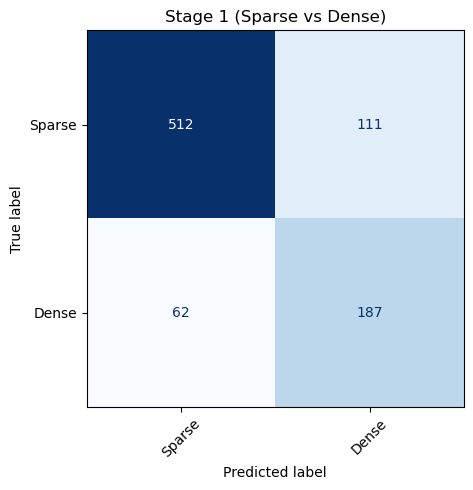

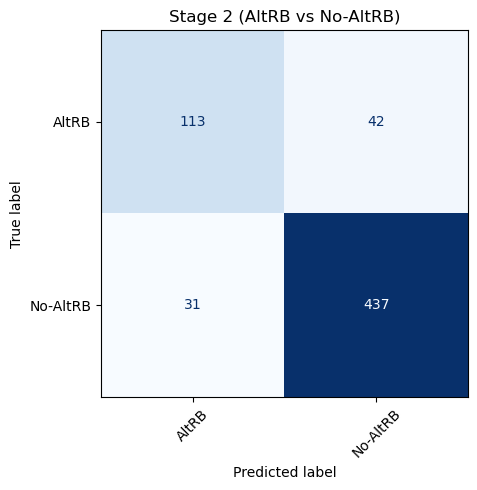

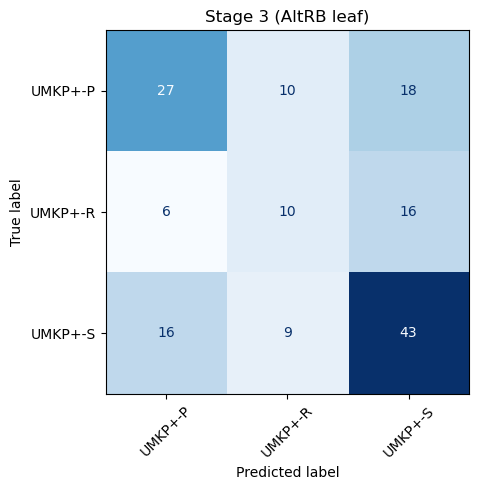

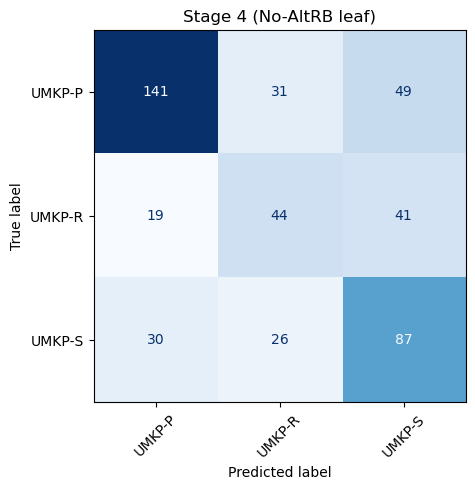

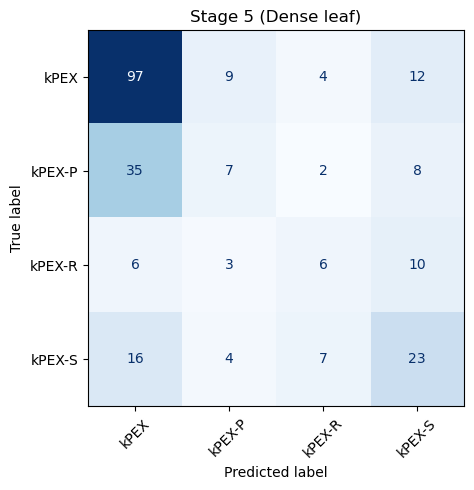

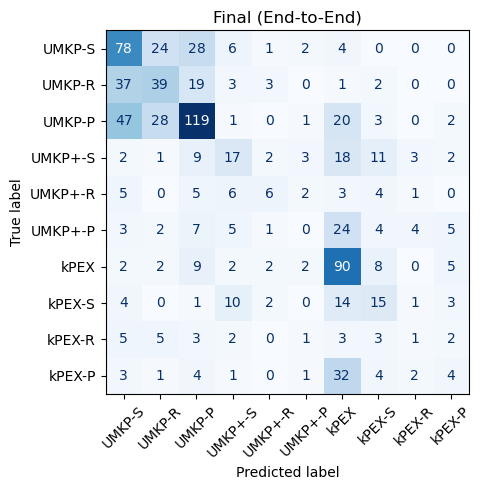


Stage-wise Summary Metrics

                         Stage  Samples  Accuracy  Avg Precision  Avg Recall  \
0    Stage 1 (Sparse vs Dense)      872  0.801606       0.759751    0.786417   
1  Stage 2 (AltRB vs No-AltRB)      623  0.882825       0.848520    0.831396   
2         Stage 3 (AltRB leaf)      155  0.516129       0.484763    0.478587   
3      Stage 4 (No-AltRB leaf)      468  0.581197       0.556425    0.556493   
4         Stage 5 (Dense leaf)      249  0.534137       0.420992    0.407424   
5           Final (End-to-End)      872  0.423165       0.302438    0.305104   

     Avg F1  
0  0.769601  
1  0.839384  
2  0.480068  
3  0.553050  
4  0.402224  
5  0.293168  


In [248]:
summary_df, per_class_reports = evaluate_hierarchical_stages(
    results_df.loc[X_test.index],
    hclf5_strat_y,
    X_test[feature_cols].values,
    algorithms
)


In [249]:
per_class_reports

{'Stage 1 (Sparse vs Dense)':               precision    recall  f1-score     support
 Sparse         0.891986  0.821830  0.855472  623.000000
 Dense          0.627517  0.751004  0.683729  249.000000
 accuracy       0.801606  0.801606  0.801606    0.801606
 macro avg      0.759751  0.786417  0.769601  872.000000
 weighted avg   0.816467  0.801606  0.806431  872.000000,
 'Stage 2 (AltRB vs No-AltRB)':               precision    recall  f1-score     support
 AltRB          0.784722  0.729032  0.755853  155.000000
 No-AltRB       0.912317  0.933761  0.922914  468.000000
 accuracy       0.882825  0.882825  0.882825    0.882825
 macro avg      0.848520  0.831396  0.839384  623.000000
 weighted avg   0.880572  0.882825  0.881350  623.000000,
 'Stage 3 (AltRB leaf)':               precision    recall  f1-score     support
 UMKP+-P        0.551020  0.490909  0.519231   55.000000
 UMKP+-R        0.344828  0.312500  0.327869   32.000000
 UMKP+-S        0.558442  0.632353  0.593103   68.000000
 a

In [250]:
save_stage_reports(
    report_obj=per_class_reports,
    file_name="hierarchical_per_class_report_test_set",
    output_dir='../outputs/RF_results/hier5/strat_y',
    to_excel=True
)



Saved stage report to: ../outputs/RF_results/hier5/strat_y\hierarchical_per_class_report_test_set.xlsx


In [251]:
save_stage_reports(
    report_obj=summary_df,
    file_name="hierarchical_summary_report_test_set",
    output_dir='../outputs/RF_results/hier5/strat_y',
    to_excel=True
)


Saved stage report to: ../outputs/RF_results/hier5/strat_y\hierarchical_summary_report_test_set.xlsx


In [252]:
classification_metrics, time_metrics, predictions_df, wrong_predictions_df = run_full_evaluation_hier5(
    cat_df=cat_df.loc[X_test.index],
    clf=hclf5_strat_y,
    features=data_splits.feature_cols,
    algorithms=data_splits.algorithms,
    epsilon=1e-3,
    save_files=True,               # set False if you don’t want to write files
    output_dir='../outputs/RF_results/hier5/strat_y',
    file_suffix= "inference_test_data_without_holdout" # change exp number
)

write_metrics_to_excel_file(
    classification_metrics,
    time_metrics,
    "../outputs/RF_results/hier5/model_performance_for_all_exp.xlsx",
    "Inference_test_data_strat_y"
)


Predicting final outputs...
Adding hierarchical leaf probabilities...
Adding hierarchical stage probabilities...

Classification performance:
Accuracy (counting ties as correct): 42.32%

Precision by Algorithm:
  UMKP-S: 41.94% (186 predictions)
  UMKP-R: 38.24% (102 predictions)
  UMKP-P: 58.33% (204 predictions)
  UMKP+-S: 32.08% (53 predictions)
  UMKP+-R: 35.29% (17 predictions)
  UMKP+-P: 0.00% (12 predictions)
  kPEX: 43.06% (209 predictions)
  kPEX-S: 27.78% (54 predictions)
  kPEX-R: 8.33% (12 predictions)
  kPEX-P: 17.39% (23 predictions)

Recall by Algorithm:
  UMKP-S: 54.55% (78/143 cases)
  UMKP-R: 37.50% (39/104 cases)
  UMKP-P: 53.85% (119/221 cases)
  UMKP+-S: 25.00% (17/68 cases)
  UMKP+-R: 18.75% (6/32 cases)
  UMKP+-P: 0.00% (0/55 cases)
  kPEX: 73.77% (90/122 cases)
  kPEX-S: 30.00% (15/50 cases)
  kPEX-R: 4.00% (1/25 cases)
  kPEX-P: 9.43% (5/53 cases)
Time Metrics:
  Total Predicted Time = 71227.80
  Total Optimal Time   = 20515.40
  Time Ratio (pred/opt)= 3.472
  

#### Inference on Entire Dataset

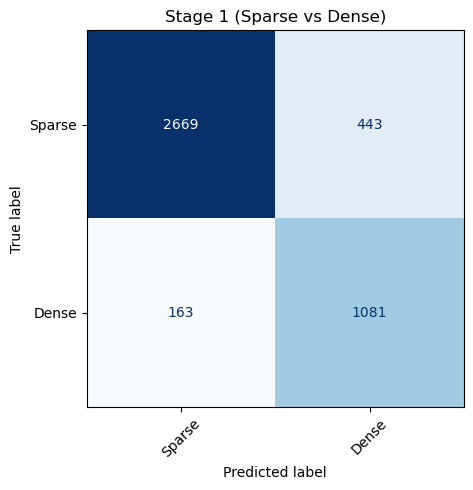

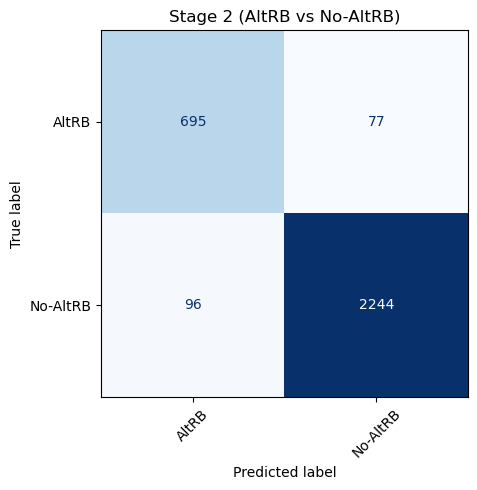

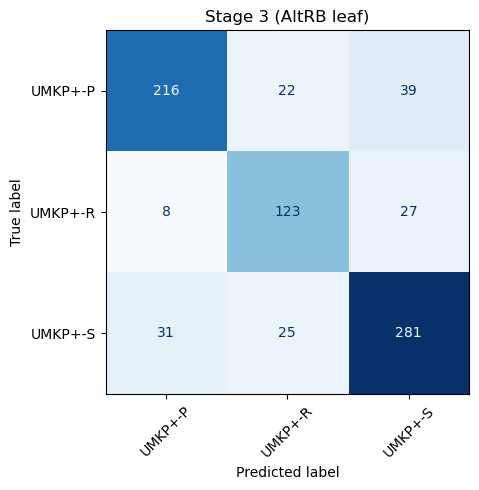

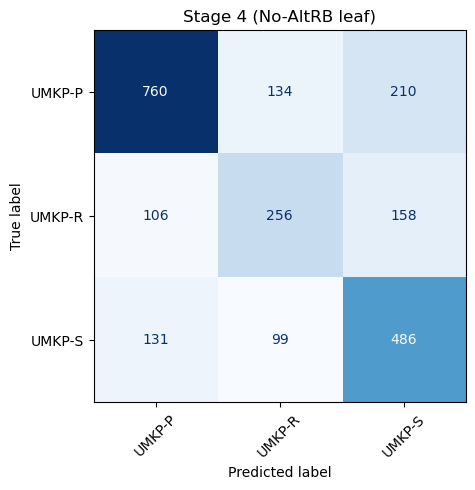

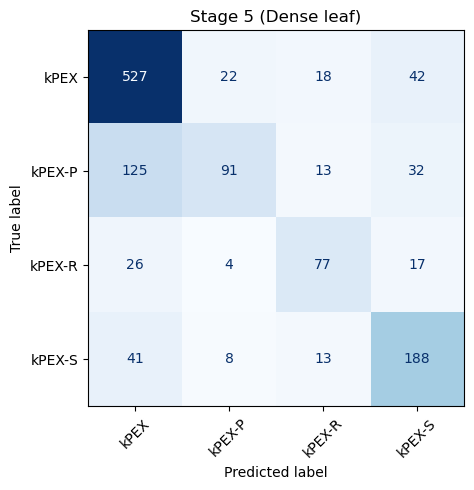

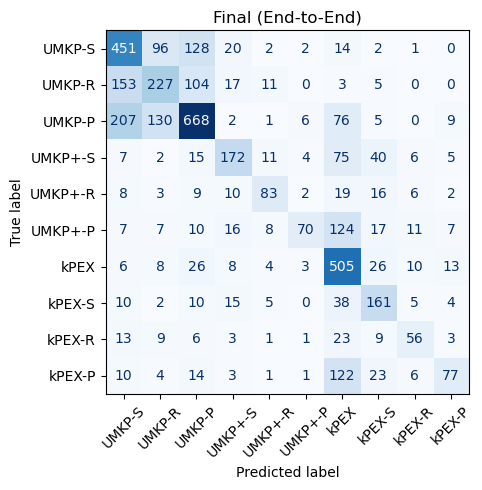


Stage-wise Summary Metrics

                         Stage  Samples  Accuracy  Avg Precision  Avg Recall  \
0    Stage 1 (Sparse vs Dense)     4356  0.860882       0.825881    0.863309   
1  Stage 2 (AltRB vs No-AltRB)     3112  0.944409       0.922730    0.929617   
2         Stage 3 (AltRB leaf)      772  0.803109       0.793462    0.797364   
3      Stage 4 (No-AltRB leaf)     2340  0.641880       0.618297    0.619828   
4         Stage 5 (Dense leaf)     1244  0.709807       0.692790    0.646745   
5           Final (End-to-End)     4356  0.567034       0.597502    0.517977   

     Avg F1  
0  0.839559  
1  0.926099  
2  0.794556  
3  0.616669  
4  0.651131  
5  0.530319  


In [253]:
X_full = results_df[feature_cols].values

summary_df, per_class_reports = evaluate_hierarchical_stages(
    results_df,
    hclf5_strat_y,
    X_full,
    algorithms
)


In [254]:
per_class_reports

{'Stage 1 (Sparse vs Dense)':               precision    recall  f1-score      support
 Sparse         0.942444  0.857648  0.898048  3112.000000
 Dense          0.709318  0.868971  0.781069  1244.000000
 accuracy       0.860882  0.860882  0.860882     0.860882
 macro avg      0.825881  0.863309  0.839559  4356.000000
 weighted avg   0.875867  0.860882  0.864641  4356.000000,
 'Stage 2 (AltRB vs No-AltRB)':               precision    recall  f1-score      support
 AltRB          0.878635  0.900259  0.889315   772.000000
 No-AltRB       0.966825  0.958974  0.962884  2340.000000
 accuracy       0.944409  0.944409  0.944409     0.944409
 macro avg      0.922730  0.929617  0.926099  3112.000000
 weighted avg   0.944947  0.944409  0.944633  3112.000000,
 'Stage 3 (AltRB leaf)':               precision    recall  f1-score     support
 UMKP+-P        0.847059  0.779783  0.812030  277.000000
 UMKP+-R        0.723529  0.778481  0.750000  158.000000
 UMKP+-S        0.809798  0.833828  0.821637  3

In [255]:
save_stage_reports(
    report_obj=per_class_reports,
    file_name="hierarchical_per_class_report_entire_data",
    output_dir='../outputs/RF_results/hier5/strat_y',
    to_excel=True
)



Saved stage report to: ../outputs/RF_results/hier5/strat_y\hierarchical_per_class_report_entire_data.xlsx


In [256]:
save_stage_reports(
    report_obj=summary_df,
    file_name="hierarchical_summary_report_entire_data",
    output_dir='../outputs/RF_results/hier5/strat_y',
    to_excel=True
)


Saved stage report to: ../outputs/RF_results/hier5/strat_y\hierarchical_summary_report_entire_data.xlsx


In [257]:
classification_metrics, time_metrics, predictions_df, wrong_predictions_df = run_full_evaluation_hier5(
    cat_df=cat_df,
    clf=hclf5_strat_y,
    features=data_splits.feature_cols,
    algorithms=data_splits.algorithms,
    epsilon=1e-3,
    save_files=True,               # set False if you don’t want to write files
    output_dir='../outputs/RF_results/hier5/strat_y',
    file_suffix= "inference_entire_data_without_holdout" # change exp number
)

write_metrics_to_excel_file(
    classification_metrics,
    time_metrics,
    "../outputs/RF_results/hier5/model_performance_for_all_exp.xlsx",
    "Inference_entire_data_strat_y"
)


Predicting final outputs...
Adding hierarchical leaf probabilities...
Adding hierarchical stage probabilities...

Classification performance:
Accuracy (counting ties as correct): 56.75%

Precision by Algorithm:
  UMKP-S: 51.72% (872 predictions)
  UMKP-R: 46.52% (488 predictions)
  UMKP-P: 67.47% (990 predictions)
  UMKP+-S: 64.66% (266 predictions)
  UMKP+-R: 65.35% (127 predictions)
  UMKP+-P: 78.65% (89 predictions)
  kPEX: 50.75% (999 predictions)
  kPEX-S: 52.96% (304 predictions)
  kPEX-R: 55.45% (101 predictions)
  kPEX-P: 64.17% (120 predictions)

Recall by Algorithm:
  UMKP-S: 62.99% (451/716 cases)
  UMKP-R: 43.65% (227/520 cases)
  UMKP-P: 60.51% (668/1104 cases)
  UMKP+-S: 51.34% (173/337 cases)
  UMKP+-R: 52.53% (83/158 cases)
  UMKP+-P: 25.54% (71/278 cases)
  kPEX: 83.01% (508/612 cases)
  kPEX-S: 64.54% (162/251 cases)
  kPEX-R: 45.60% (57/125 cases)
  kPEX-P: 29.77% (78/262 cases)
Time Metrics:
  Total Predicted Time = 222117.16
  Total Optimal Time   = 111146.05
  Tim

### **Balanced train-test split based on Y and K**

In [258]:
from sklearn.model_selection import train_test_split
import pandas as pd

def prepare_train_test_strat_Y_K_hier(cat_df,
                       weight_col='weight',
                       test_size=0.2,
                       random_state=42,
                       for_nn=False,
                       kcore_list=None,
                       tie_tolerance=0.00):

    if kcore_list:
        feature_cols = ['k_value', 'n', 'm', 'd_avg', 'd_max', 'core_max',
                        'core_min', 'shell_num', 'shell_avgSize',
                        'shell_maxSize', 'shell_minSize', 'shell_stdSize', 'kcore_list']
    elif for_nn:
        feature_cols = ['k_value', 'n', 'm', 'd_avg', 'd_max', 'core_max',
                        'core_min', 'shell_num', 'shell_avgSize',
                        'shell_maxSize', 'shell_minSize', 'shell_stdSize', 'fastest_time']
    else:
        feature_cols = ['k_value', 'n', 'm', 'd_avg', 'd_max', 'core_max',
                        'core_min', 'shell_num', 'shell_avgSize',
                        'shell_maxSize', 'shell_minSize', 'shell_stdSize']

    X = cat_df[feature_cols]

    y_algo = cat_df['y_algo']
    y_group = cat_df['y_group']
    y_sparse_subgroup = cat_df['y_sparse_subgroup']

    weight_group = cat_df['weight_group']
    weight_sparse = cat_df['weight_sparse_subgroup']
    weight_altRB = cat_df['weight_altRB']
    weight_noAltRB = cat_df['weight_noAltRB']
    weight_dense = cat_df['weight_dense']

    stratify_var = y_algo.astype(str) + "_k" + cat_df['k_value'].astype(str)

    X_train, X_test, \
    y_algo_train, y_algo_test = train_test_split(
        X, y_algo,
        test_size=test_size,
        random_state=random_state,
        stratify=stratify_var
    )

    idx_train = X_train.index
    idx_test = X_test.index

    return (
        X_train, X_test,
        y_algo_train, y_algo_test,

        y_group.loc[idx_train], y_group.loc[idx_test],
        y_sparse_subgroup.loc[idx_train], y_sparse_subgroup.loc[idx_test],

        weight_group.loc[idx_train], weight_group.loc[idx_test],
        weight_sparse.loc[idx_train], weight_sparse.loc[idx_test],
        weight_altRB.loc[idx_train], weight_altRB.loc[idx_test],
        weight_noAltRB.loc[idx_train], weight_noAltRB.loc[idx_test],
        weight_dense.loc[idx_train], weight_dense.loc[idx_test],
    )


In [259]:
# from data_splits import prepare_train_test_strat_Y_K_hier

X_train, X_test, \
y_algo_train, y_algo_test, \
y_group_train, y_group_test, \
y_sparse_subgroup_train, y_sparse_subgroup_test, \
weight_group_train, weight_group_test, \
weight_sparse_train, weight_sparse_test, \
weight_altRB_train, weight_altRB_test, \
weight_noAltRB_train, weight_noAltRB_test, \
weight_dense_train, weight_dense_test = prepare_train_test_strat_Y_K_hier(
                                                                            cat_df,
                                                                            tie_tolerance = 0.0  # algorithms within tie_tolerance% of min treated as ties
                                                                        )

In [260]:
hclf5_strat_y_K = HierarchicalClassifier5(
    group_clf=group_clf,
    sparse_subgroup_clf=sparse_subgroup_clf,
    altRB_clf=altRB_clf,
    noAltRB_clf=noAltRB_clf,
    dense_clf=dense_clf,
    tau_group=0.0,
    tau_sparse=0.0,
    tau_algo=0.0,
    fallback_label="SAFE_DEFAULT_ALGO"
)


In [261]:
hclf5_strat_y_K.fit(
    X_train.values,                 # ensure numpy array
    y_group_train.values,
    y_sparse_subgroup_train.values,
    y_algo_train.values,

    weight_group=weight_group_train.values,
    weight_sparse=weight_sparse_train.values,
    weight_altRB=weight_altRB_train.values,
    weight_noAltRB=weight_noAltRB_train.values,
    weight_dense=weight_dense_train.values
)


In [262]:
hclf5_strat_y_K.predict_proba(X_test.values)

array([[6.92835120e-03, 1.10683492e-02, 3.07484276e-02, ...,
        6.98999907e-02, 6.25023011e-02, 4.77595752e-02],
       [8.37022367e-03, 1.57448029e-02, 6.02727015e-03, ...,
        6.02948565e-03, 1.10431379e-02, 7.93057268e-03],
       [4.94243280e-03, 8.47814128e-02, 7.70112183e-01, ...,
        4.14212608e-04, 1.76526207e-04, 9.36462846e-04],
       ...,
       [6.57505401e-03, 1.14501521e-02, 2.65928714e-02, ...,
        4.31874061e-03, 1.34366018e-02, 3.61677724e-03],
       [2.59178158e-02, 1.35165273e-02, 4.72271776e-02, ...,
        6.68137273e-02, 5.85189239e-02, 9.16566969e-02],
       [3.39367112e-02, 1.37810790e-01, 4.68009398e-02, ...,
        5.30320283e-02, 5.13248153e-02, 2.71108198e-02]])

#### Inference on 20% Dataset

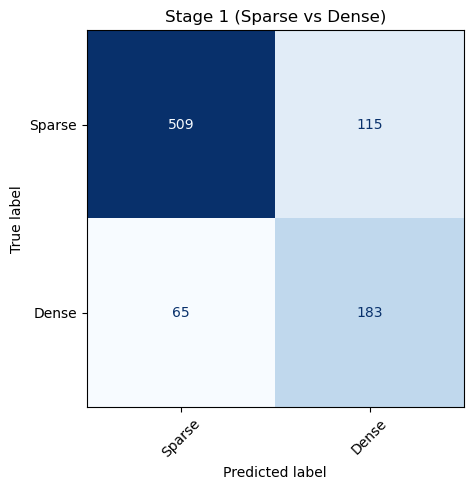

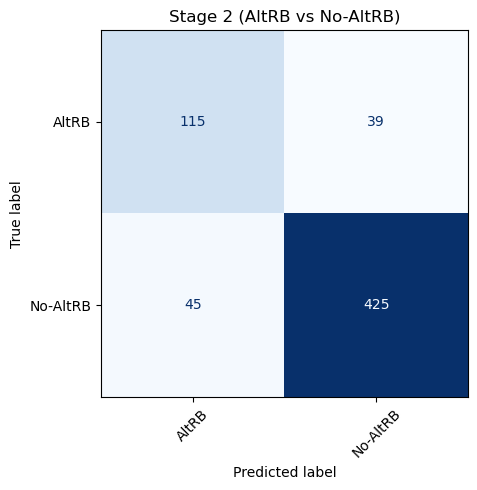

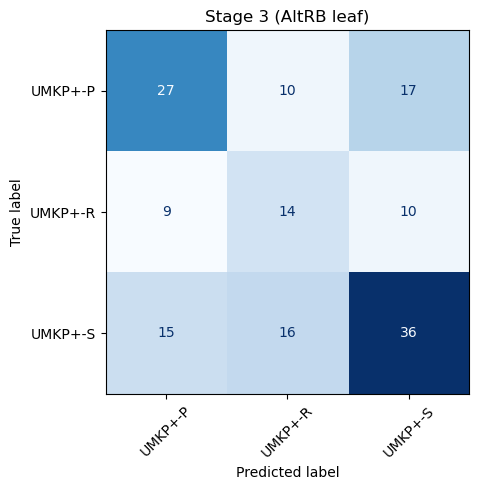

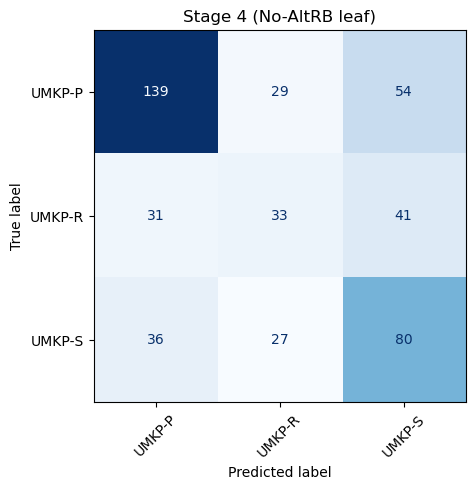

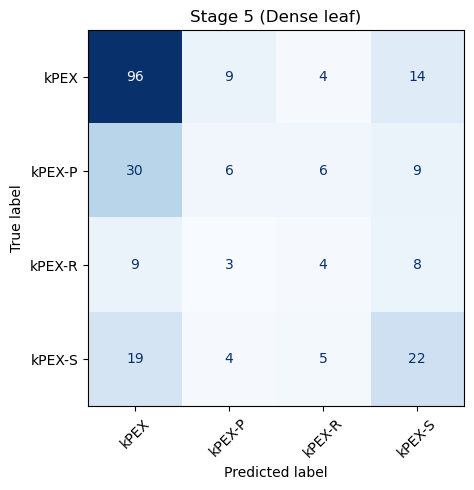

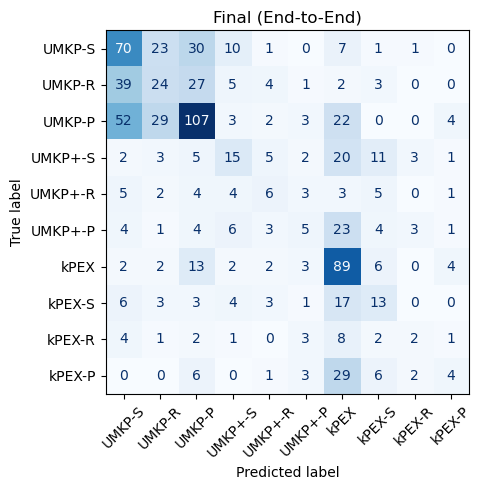


Stage-wise Summary Metrics

                         Stage  Samples  Accuracy  Avg Precision  Avg Recall  \
0    Stage 1 (Sparse vs Dense)      872  0.793578       0.750427    0.776804   
1  Stage 2 (AltRB vs No-AltRB)      624  0.865385       0.817349    0.825504   
2         Stage 3 (AltRB leaf)      154  0.500000       0.483613    0.487185   
3      Stage 4 (No-AltRB leaf)      470  0.536170       0.500896    0.499951   
4         Stage 5 (Dense leaf)      248  0.516129       0.380431    0.376200   
5           Final (End-to-End)      872  0.384174       0.300732    0.284370   

     Avg F1  
0  0.760040  
1  0.821274  
2  0.483898  
3  0.497628  
4  0.367689  
5  0.277743  


In [263]:
summary_df, per_class_reports = evaluate_hierarchical_stages(
    results_df.loc[X_test.index],
    hclf5_strat_y_K,
    X_test[feature_cols].values,
    algorithms
)


In [264]:
per_class_reports

{'Stage 1 (Sparse vs Dense)':               precision    recall  f1-score     support
 Sparse         0.886760  0.815705  0.849750  624.000000
 Dense          0.614094  0.737903  0.670330  248.000000
 accuracy       0.793578  0.793578  0.793578    0.793578
 macro avg      0.750427  0.776804  0.760040  872.000000
 weighted avg   0.809212  0.793578  0.798722  872.000000,
 'Stage 2 (AltRB vs No-AltRB)':               precision    recall  f1-score     support
 AltRB          0.718750  0.746753  0.732484  154.000000
 No-AltRB       0.915948  0.904255  0.910064  470.000000
 accuracy       0.865385  0.865385  0.865385    0.865385
 macro avg      0.817349  0.825504  0.821274  624.000000
 weighted avg   0.867281  0.865385  0.866238  624.000000,
 'Stage 3 (AltRB leaf)':               precision    recall  f1-score  support
 UMKP+-P        0.529412  0.500000  0.514286     54.0
 UMKP+-R        0.350000  0.424242  0.383562     33.0
 UMKP+-S        0.571429  0.537313  0.553846     67.0
 accuracy     

In [265]:
save_stage_reports(
    report_obj=per_class_reports,
    file_name="hierarchical_per_class_report_test_set",
    output_dir='../outputs/RF_results/hier5/strat_y_K',
    to_excel=True
)



Saved stage report to: ../outputs/RF_results/hier5/strat_y_K\hierarchical_per_class_report_test_set.xlsx


In [266]:
save_stage_reports(
    report_obj=summary_df,
    file_name="hierarchical_summary_report_test_set",
    output_dir='../outputs/RF_results/hier5/strat_y_K',
    to_excel=True
)


Saved stage report to: ../outputs/RF_results/hier5/strat_y_K\hierarchical_summary_report_test_set.xlsx


In [267]:
classification_metrics, time_metrics, predictions_df, wrong_predictions_df = run_full_evaluation_hier5(
    cat_df=cat_df.loc[X_test.index],
    clf=hclf5_strat_y_K,
    features=data_splits.feature_cols,
    algorithms=data_splits.algorithms,
    epsilon=1e-3,
    save_files=True,               # set False if you don’t want to write files
    output_dir='../outputs/RF_results/hier5/strat_y_K',
    file_suffix= "inference_test_data_without_holdout" # change exp number
)

write_metrics_to_excel_file(
    classification_metrics,
    time_metrics,
    "../outputs/RF_results/hier5/model_performance_for_all_exp.xlsx",
    "Inference_test_data_strat_y_K"
)


Predicting final outputs...
Adding hierarchical leaf probabilities...
Adding hierarchical stage probabilities...

Classification performance:
Accuracy (counting ties as correct): 38.42%

Precision by Algorithm:
  UMKP-S: 38.04% (184 predictions)
  UMKP-R: 27.27% (88 predictions)
  UMKP-P: 53.23% (201 predictions)
  UMKP+-S: 30.00% (50 predictions)
  UMKP+-R: 22.22% (27 predictions)
  UMKP+-P: 20.83% (24 predictions)
  kPEX: 40.45% (220 predictions)
  kPEX-S: 25.49% (51 predictions)
  kPEX-R: 18.18% (11 predictions)
  kPEX-P: 25.00% (16 predictions)

Recall by Algorithm:
  UMKP-S: 48.95% (70/143 cases)
  UMKP-R: 22.86% (24/105 cases)
  UMKP-P: 48.20% (107/222 cases)
  UMKP+-S: 22.39% (15/67 cases)
  UMKP+-R: 18.18% (6/33 cases)
  UMKP+-P: 9.26% (5/54 cases)
  kPEX: 72.36% (89/123 cases)
  kPEX-S: 26.00% (13/50 cases)
  kPEX-R: 8.33% (2/24 cases)
  kPEX-P: 7.84% (4/51 cases)
Time Metrics:
  Total Predicted Time = 81167.61
  Total Optimal Time   = 21427.86
  Time Ratio (pred/opt)= 3.788
 

#### Inference on Entire Dataset

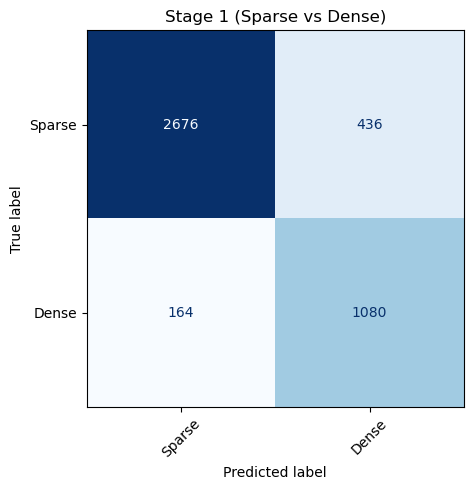

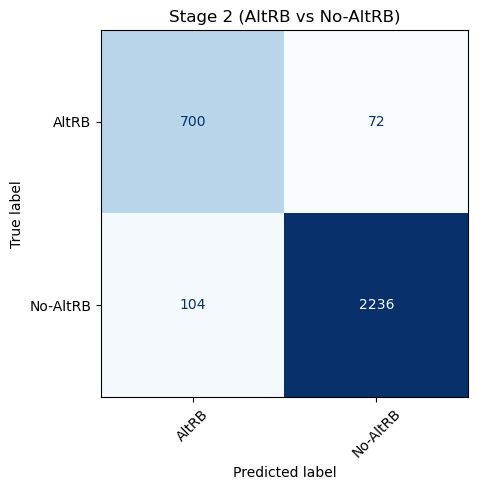

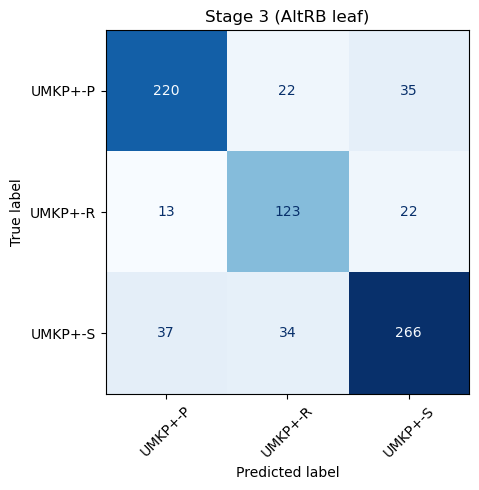

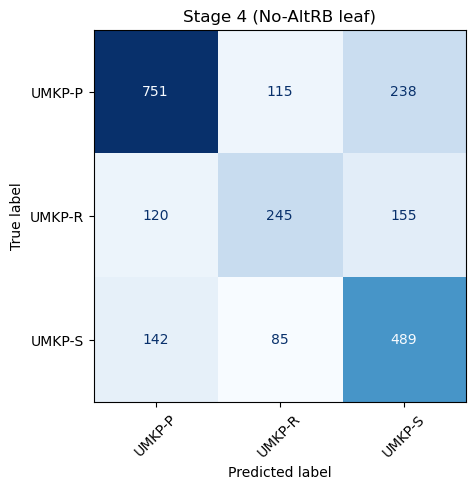

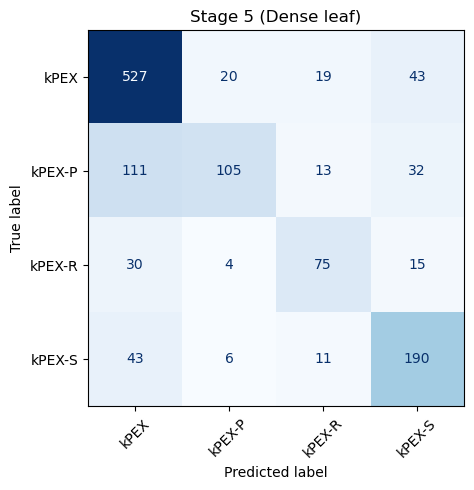

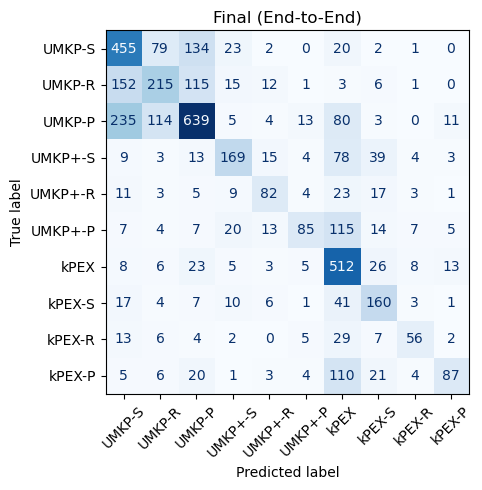


Stage-wise Summary Metrics

                         Stage  Samples  Accuracy  Avg Precision  Avg Recall  \
0    Stage 1 (Sparse vs Dense)     4356  0.862259       0.827327    0.864032   
1  Stage 2 (AltRB vs No-AltRB)     3112  0.943445       0.919725    0.931146   
2         Stage 3 (AltRB leaf)      772  0.788860       0.775165    0.787341   
3      Stage 4 (No-AltRB leaf)     2340  0.634615       0.615449    0.611456   
4         Stage 5 (Dense leaf)     1244  0.721061       0.708288    0.658123   
5           Final (End-to-End)     4356  0.564738       0.598309    0.522074   

     Avg F1  
0  0.840901  
1  0.925230  
2  0.780140  
3  0.609761  
4  0.666401  
5  0.537068  


In [268]:
X_full = results_df[feature_cols].values

summary_df, per_class_reports = evaluate_hierarchical_stages(
    results_df,
    hclf5_strat_y_K,
    X_full,
    algorithms
)


In [269]:
per_class_reports

{'Stage 1 (Sparse vs Dense)':               precision    recall  f1-score      support
 Sparse         0.942254  0.859897  0.899194  3112.000000
 Dense          0.712401  0.868167  0.782609  1244.000000
 accuracy       0.862259  0.862259  0.862259     0.862259
 macro avg      0.827327  0.864032  0.840901  4356.000000
 weighted avg   0.876612  0.862259  0.865899  4356.000000,
 'Stage 2 (AltRB vs No-AltRB)':               precision    recall  f1-score      support
 AltRB          0.870647  0.906736  0.888325   772.000000
 No-AltRB       0.968804  0.955556  0.962134  2340.000000
 accuracy       0.943445  0.943445  0.943445     0.943445
 macro avg      0.919725  0.931146  0.925230  3112.000000
 weighted avg   0.944454  0.943445  0.943824  3112.000000,
 'Stage 3 (AltRB leaf)':               precision    recall  f1-score    support
 UMKP+-P        0.814815  0.794224  0.804388  277.00000
 UMKP+-R        0.687151  0.778481  0.729970  158.00000
 UMKP+-S        0.823529  0.789318  0.806061  337.

In [270]:
save_stage_reports(
    report_obj=per_class_reports,
    file_name="hierarchical_per_class_report_entire_data",
    output_dir='../outputs/RF_results/hier5/strat_y_K',
    to_excel=True
)



Saved stage report to: ../outputs/RF_results/hier5/strat_y_K\hierarchical_per_class_report_entire_data.xlsx


In [271]:
save_stage_reports(
    report_obj=summary_df,
    file_name="hierarchical_summary_report_entire_data",
    output_dir='../outputs/RF_results/hier5/strat_y_K',
    to_excel=True
)


Saved stage report to: ../outputs/RF_results/hier5/strat_y_K\hierarchical_summary_report_entire_data.xlsx


In [272]:
classification_metrics, time_metrics, predictions_df, wrong_predictions_df = run_full_evaluation_hier5(
    cat_df=cat_df,
    clf=hclf5_strat_y_K,
    features=data_splits.feature_cols,
    algorithms=data_splits.algorithms,
    epsilon=1e-3,
    save_files=True,               # set False if you don’t want to write files
    output_dir='../outputs/RF_results/hier5/strat_y_K',
    file_suffix= "inference_entire_data_without_holdout" # change exp number
)

write_metrics_to_excel_file(
    classification_metrics,
    time_metrics,
    "../outputs/RF_results/hier5/model_performance_for_all_exp.xlsx",
    "Inference_entire_data_strat_y"
)


Predicting final outputs...
Adding hierarchical leaf probabilities...
Adding hierarchical stage probabilities...

Classification performance:
Accuracy (counting ties as correct): 56.52%

Precision by Algorithm:
  UMKP-S: 49.89% (912 predictions)
  UMKP-R: 48.86% (440 predictions)
  UMKP-P: 66.08% (967 predictions)
  UMKP+-S: 65.25% (259 predictions)
  UMKP+-R: 58.57% (140 predictions)
  UMKP+-P: 69.67% (122 predictions)
  kPEX: 50.84% (1011 predictions)
  kPEX-S: 54.24% (295 predictions)
  kPEX-R: 64.37% (87 predictions)
  kPEX-P: 70.73% (123 predictions)

Recall by Algorithm:
  UMKP-S: 63.55% (455/716 cases)
  UMKP-R: 41.35% (215/520 cases)
  UMKP-P: 57.88% (639/1104 cases)
  UMKP+-S: 50.45% (170/337 cases)
  UMKP+-R: 51.90% (82/158 cases)
  UMKP+-P: 30.94% (86/278 cases)
  kPEX: 84.15% (515/612 cases)
  kPEX-S: 63.75% (160/251 cases)
  kPEX-R: 45.60% (57/125 cases)
  kPEX-P: 33.59% (88/262 cases)
Time Metrics:
  Total Predicted Time = 233127.59
  Total Optimal Time   = 111146.05
  Ti